![Imgur](https://i.imgur.com/h4PPC71.png)
#**19-modul. Unsupervised learning. Clustering**
# 19.8. Modul boʻyicha yakuniy amaliy vazifa. Mijozlarni xarajat turlariga qarab segmentlash

**Ushbu vazifa orqali siz:**

✔️ klasterlash;

✔️ maʼlumotlarni normallashtirish;

✔️ klaster tahlili;

✔️ vizualizatsiya kabi real data sayns loyihalari uchun zarur texnik ko‘nikmalarga ega bo‘lasiz.

## **Dataset: Wholesale Customers Data**  
- **Manba:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/wholesale+customers)  
- **Hajmi:** **22 KB**
- **Format:** CSV  
- **Tavsif:** bu dataset **ulgurji savdo mijozlarini** xarajatlar bo‘yicha klasterlash uchun ishlatiladi.  
  U quyidagi xarajat kategoriyalarini o‘z ichiga oladi:  
  - **channel** (mijoz turi: 1 – HoReCa (mehmonxona, restoran, kafelar) yoki 2 – chakana savdo)  
  - **region** (hudud: 1 – Lisbon, 2 – Oporto, 3 – boshqa)  
  - **fresh** (yangi mahsulotlarga sarf qilingan summa)  
  - **milk** (sut mahsulotlariga sarf qilingan summa)  
  - **grocery** (oziq-ovqat mahsulotlariga sarf qilingan summa)  
  - **frozen** (muzlatilgan mahsulotlarga sarf qilingan summa)  
  - **Detergents_Paper** (kimyoviy tozalash va qog‘oz mahsulotlari)  
  - **delicassen** (delikates mahsulotlar)  

---

### **Vazifa: mijozlarni xarajat turlariga qarab segmentlash**  
Maqsad – **mijozlarni xarajat qiladigan mahsulotlar bo‘yicha klasterlash va marketologlarga tavsiyalar berish**  

---

### **Klasterlash bosqichlari**  
1) **Maʼlumotlarni tayyorlash**  
   - `Channel` va `Region` ustunlarini olib tashlang yoki kodlang.  
   - Har bir xarajat ustunini **normalizatsiya qiling**.  

2) **K-means klasterlashni amalga oshirish**  
   - K-means yordamida mijozlarni **xarajat qilish odatlari** bo‘yicha segmentlarga ajrating.  

3) **Natijalarni vizualizatsiya qilish**  
   - **Pairplot yoki scatter plot** yordamida klasterlarni ko‘rsating.  
   - Har bir segmentning xarajatlar bo‘yicha o‘rtacha qiymatini diagrammada aks ettiring.

---

###*** ESLATMA**: *Ushbu amaliy vazifada siz oʻtmagan mavzulardan ham savollar va vazifalar boʻlishi mumkin! Bu savollarni mustaqil oʻrganishingiz kerak boʻladi. Bunday vazifalar mustaqil izlanish koʻnikmangizni oshirish uchun tayyorlandi!*

In [8]:
import pandas as pd
df = pd.read_csv("https://raw.githubusercontent.com/alishermutalov/praktikum-datasets/refs/heads/praktikum/Wholesale_customers_data.csv")
df.head()


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


Hajmi: (440, 8)
Boʻsh qiymatlar: 0 | Dublikatlar: 0

Asimmetriya (skewness) – barcha ustunlar kuchli oʻngga ogʻgan:
Fresh                2.56
Milk                 4.05
Grocery              3.59
Frozen               5.91
Detergents_Paper     3.63
Delicassen          11.15
dtype: float64


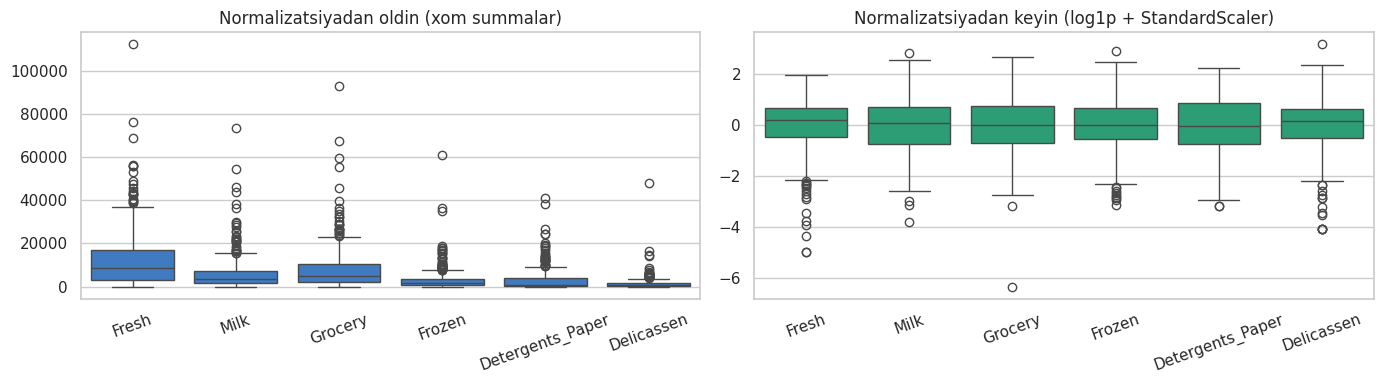

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.00,440.00,440.00,440.00,440.00,440.00
mean,0.00,-0.00,-0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-5.00,-3.79,-6.36,-3.16,-3.17,-4.09
25%,-0.47,-0.73,-0.69,-0.54,-0.73,-0.51
50%,0.21,0.07,0.02,0.02,-0.05,0.16
75%,0.68,0.70,0.75,0.68,0.87,0.65
max,1.97,2.86,2.70,2.90,2.24,3.18


In [9]:
# ===================== 1. MAʼLUMOTLARNI TAYYORLASH =====================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")

print("Hajmi:", df.shape)
print("Boʻsh qiymatlar:", df.isna().sum().sum(), "| Dublikatlar:", df.duplicated().sum())

spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]

# Channel va Region – xarajat emas, kategorik belgilar. Ularni klasterlashdan chiqarib tashlaymiz,
# lekin keyinchalik segmentlarni talqin qilish uchun alohida saqlab qoʻyamiz.
meta = df[["Channel", "Region"]].copy()
X = df[spend_cols].copy()

print("\nAsimmetriya (skewness) – barcha ustunlar kuchli oʻngga ogʻgan:")
print(X.skew().round(2))

# K-means Evklid masofasidan foydalanadi, shuning uchun:
#  1) log1p – katta xarajatli "outlier" mijozlar taʼsirini kamaytiradi, taqsimotni simmetrik qiladi;
#  2) StandardScaler – har bir ustunni oʻrtacha=0, std=1 holatiga keltiradi (bir xil masshtab).
X_log = np.log1p(X)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)
X_scaled_df = pd.DataFrame(X_scaled, columns=spend_cols)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=X, ax=ax[0], color="#2a78d6")
ax[0].set_title("Normalizatsiyadan oldin (xom summalar)")
sns.boxplot(data=X_scaled_df, ax=ax[1], color="#1baf7a")
ax[1].set_title("Normalizatsiyadan keyin (log1p + StandardScaler)")
for a in ax:
    a.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

X_scaled_df.describe().round(2)

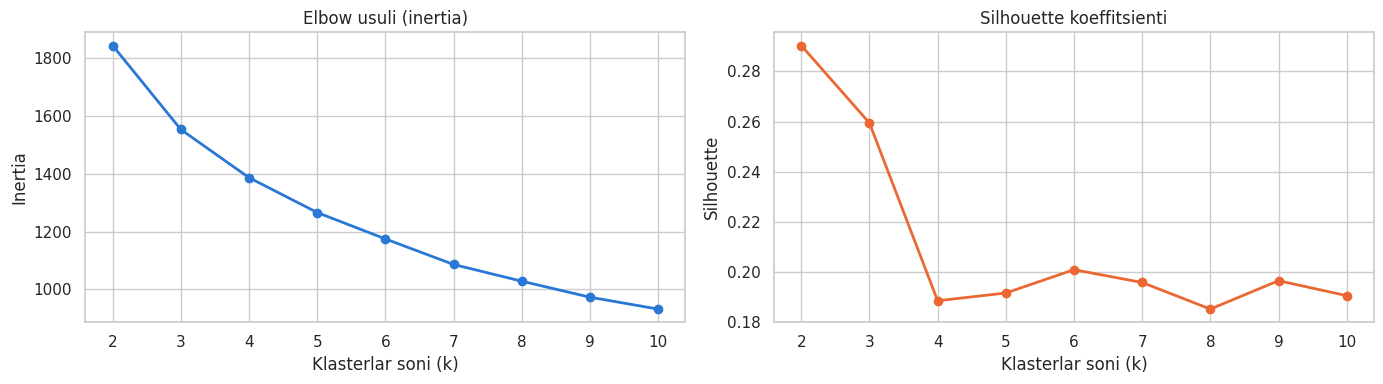

,k,inertia,silhouette
0,2,1844.1,0.290
1,3,1553.4,0.259
2,4,1386.9,0.188
3,5,1266.1,0.192
4,6,1174.8,0.201
5,7,1086.4,0.196
6,8,1028.5,0.185
7,9,973.1,0.197
8,10,932.0,0.191


In [10]:
# ===================== 2. OPTIMAL KLASTERLAR SONINI TANLASH =====================
K = range(2, 11)
inertia, sil = [], []
for k in K:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, labels))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(K, inertia, "o-", color="#2a78d6", lw=2)
ax[0].set_title("Elbow usuli (inertia)")
ax[0].set_xlabel("Klasterlar soni (k)")
ax[0].set_ylabel("Inertia")
ax[1].plot(K, sil, "o-", color="#eb6834", lw=2)
ax[1].set_title("Silhouette koeffitsienti")
ax[1].set_xlabel("Klasterlar soni (k)")
ax[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

pd.DataFrame({"k": list(K), "inertia": np.round(inertia, 1), "silhouette": np.round(sil, 3)})

**k ni tanlash.** Silhouette eng yuqori qiymatni k=2 da beradi, lekin bu ikki klaster amalda faqat `Channel` (HoReCa / chakana) boʻlinishini takrorlaydi – marketing uchun yangi maʼlumot bermaydi. Elbow grafigida egilish k=3–4 oraligʻida koʻrinadi. **k=4** ni tanlaymiz: u har bir mijoz turini (HoReCa va chakana) yana *kichik* va *yirik* xaridorlarga ajratadi – bu marketologlar uchun aniq harakat qilsa boʻladigan segmentlar.

In [11]:
# ===================== 3. K-MEANS KLASTERLASH (k = 4) =====================
k = 4
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
raw_labels = kmeans.fit_predict(X_scaled)

# Klaster raqamlarini oʻrtacha umumiy xarajat boʻyicha tartiblaymiz (0 – eng kam, 3 – eng koʻp),
# shunda natija har safar bir xil tartibda chiqadi va nomlash barqaror boʻladi.
order = X.groupby(raw_labels).mean().sum(axis=1).sort_values().index
mapping = {old: new for new, old in enumerate(order)}
df["Cluster"] = pd.Series(raw_labels).map(mapping).values

segment_names = {
    0: "0 · Kichik kafe/restoranlar",
    1: "1 · Kichik oziq-ovqat doʻkonlari",
    2: "2 · Yirik restoran/mehmonxonalar",
    3: "3 · Supermarketlar (yirik chakana)",
}
df["Segment"] = df["Cluster"].map(segment_names)
seg_order = [segment_names[i] for i in range(k)]
palette = dict(zip(seg_order, ["#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7"]))

print("Silhouette (k=4):", round(silhouette_score(X_scaled, df["Cluster"]), 3))

# Segmentlar profili: soni, ulushi, har bir kategoriya boʻyicha oʻrtacha xarajat
profile = df.groupby("Segment")[spend_cols].mean().round(0).loc[seg_order]
profile.insert(0, "Mijozlar soni", df["Segment"].value_counts().loc[seg_order])
profile.insert(1, "Ulush, %", (profile["Mijozlar soni"] / len(df) * 100).round(1))
profile["Jami oʻrtacha xarajat"] = profile[spend_cols].sum(axis=1)
display(profile)

# Channel va Region – segmentlarni talqin qilish uchun (klasterlashda ishlatilmagan)
ch = pd.crosstab(df["Segment"], df["Channel"].map({1: "HoReCa", 2: "Chakana"})).loc[seg_order]
rg = pd.crosstab(df["Segment"], df["Region"].map({1: "Lisbon", 2: "Oporto", 3: "Boshqa"})).loc[seg_order]
display(pd.concat([ch, rg], axis=1, keys=["Channel", "Region"]))

Silhouette (k=4): 0.188


,Mijozlar soni,"Ulush, %",Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Jami oʻrtacha xarajat
Segment,,,,,,,,,
0 · Kichik kafe/restoranlar,132,30.0,9633.0,1570.0,2072.0,2175.0,345.0,585.0,16380.0
1 · Kichik oziq-ovqat doʻkonlari,61,13.9,2809.0,7062.0,12349.0,566.0,5343.0,636.0,28765.0
2 · Yirik restoran/mehmonxonalar,129,29.3,19374.0,4068.0,4445.0,6184.0,723.0,2323.0,37117.0
3 · Supermarketlar (yirik chakana),118,26.8,11339.0,11759.0,16088.0,1968.0,6806.0,2164.0,50124.0


Channel        Region              
                                   Chakana HoReCa Boshqa Lisbon Oporto
Segment                                                               
0 · Kichik kafe/restoranlar              1    131     94     27     11
1 · Kichik oziq-ovqat doʻkonlari        40     21     47      8      6
2 · Yirik restoran/mehmonxonalar         7    122     91     21     17
3 · Supermarketlar (yirik chakana)      94     24     84     21     13

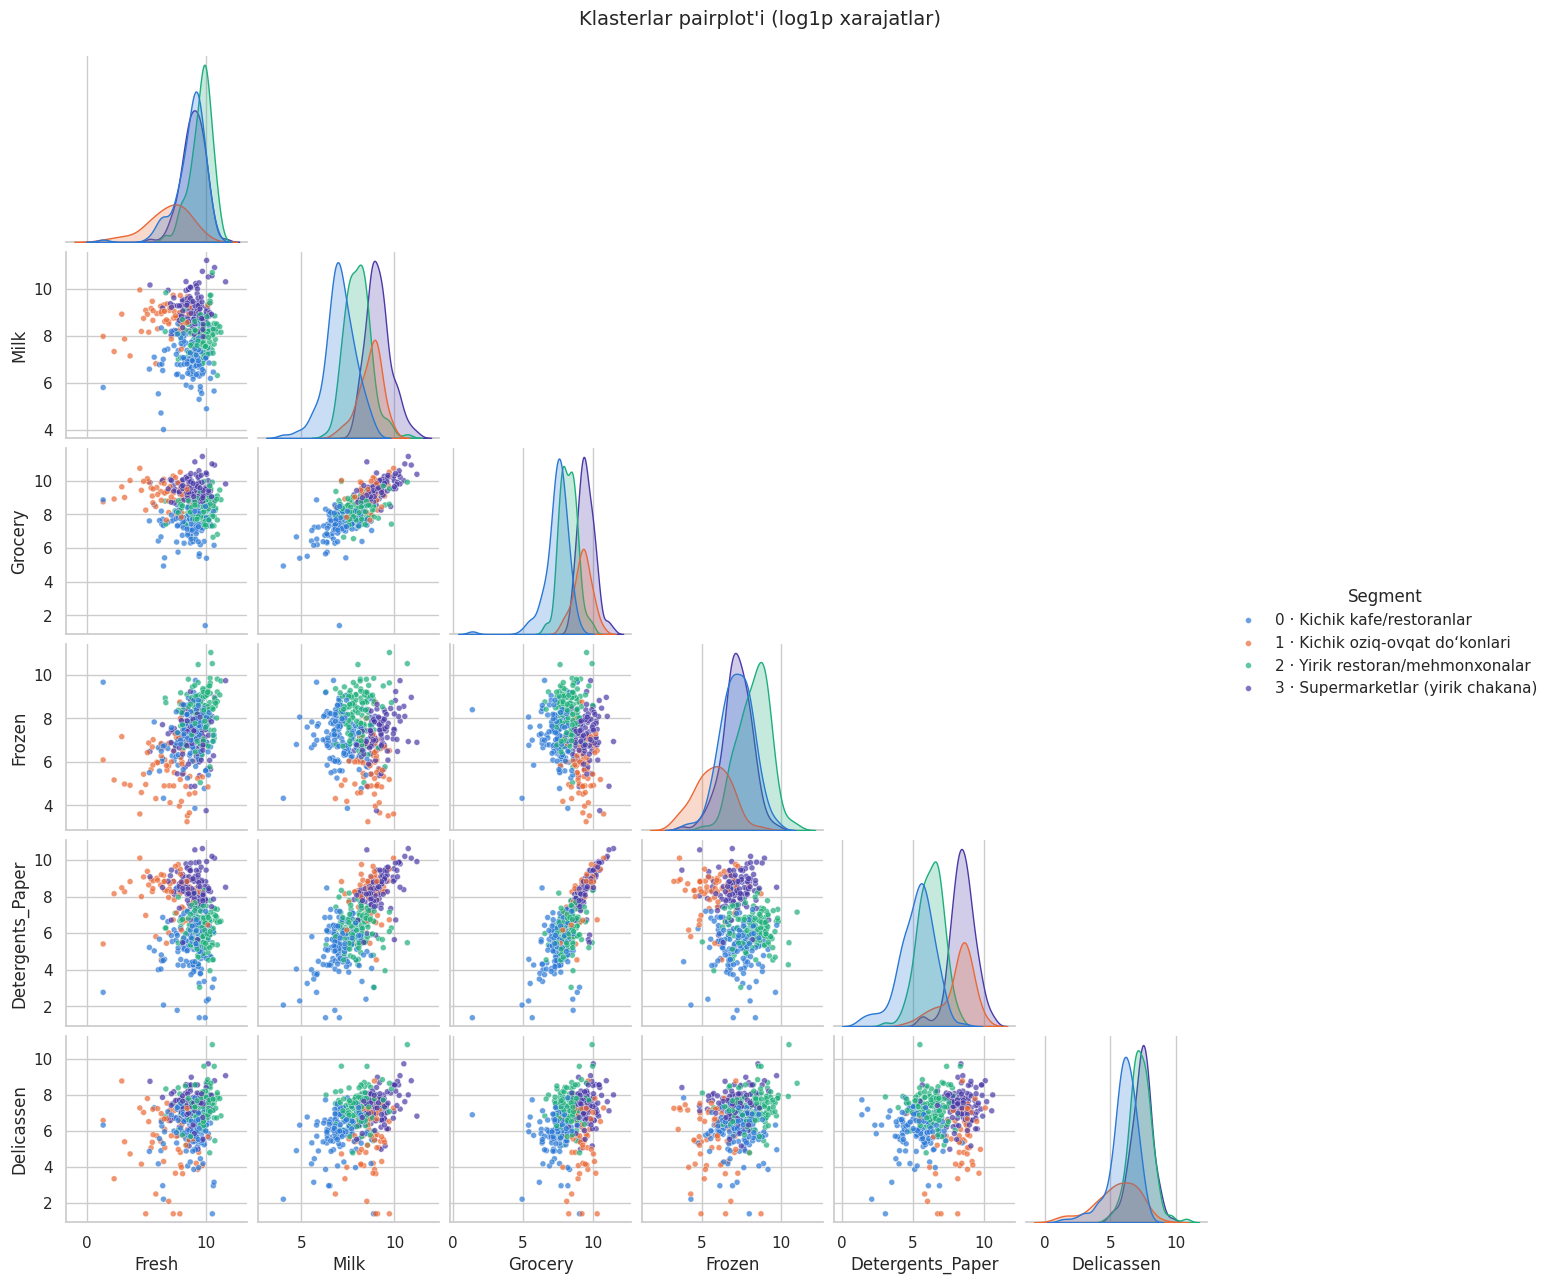

In [12]:
# ===================== 4. VIZUALIZATSIYA: PAIRPLOT =====================
# Log-masshtabdagi xarajatlar (xom summalarda nuqtalar chap pastki burchakka toʻplanib qoladi)
plot_df = X_log.copy()
plot_df["Segment"] = df["Segment"]
g = sns.pairplot(plot_df, hue="Segment", hue_order=seg_order, palette=palette,
                 corner=True, plot_kws={"s": 18, "alpha": 0.7}, diag_kind="kde", height=2.1)
g.figure.suptitle("Klasterlar pairplot'i (log1p xarajatlar)", y=1.02, fontsize=14)
plt.show()

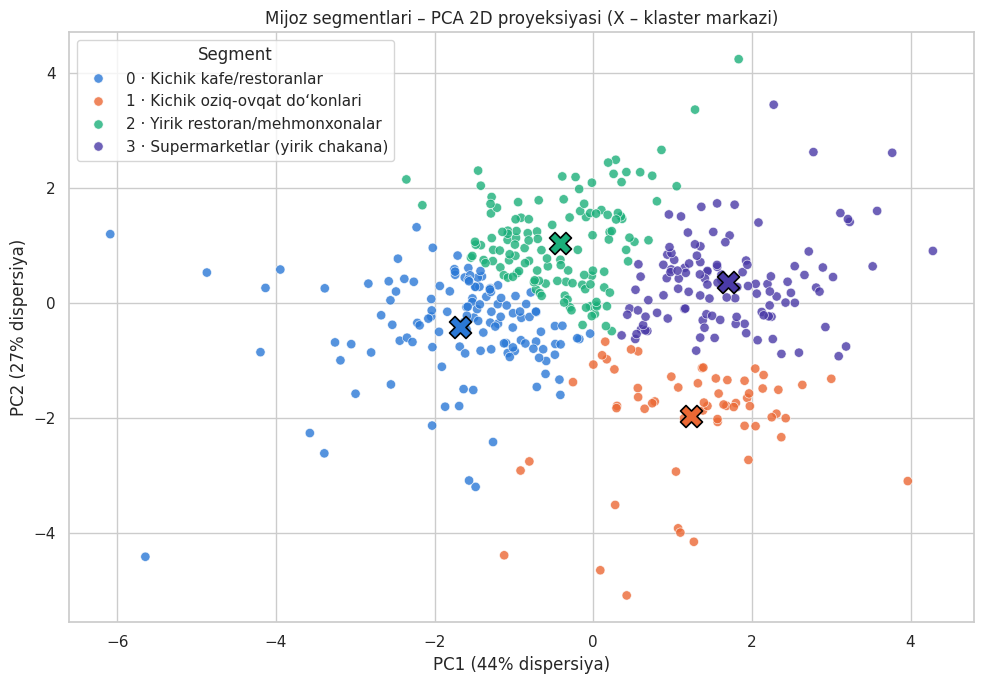

In [13]:
# ===================== 5. VIZUALIZATSIYA: PCA SCATTER PLOT =====================
pca = PCA(n_components=2, random_state=42)
pcs = pca.fit_transform(X_scaled)
centers = pca.transform(kmeans.cluster_centers_)

fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df["Segment"], hue_order=seg_order,
                palette=palette, s=45, alpha=0.8, edgecolor="white", linewidth=0.5, ax=ax)
for old, new in mapping.items():
    ax.scatter(*centers[old], marker="X", s=250, color=palette[segment_names[new]],
               edgecolor="black", linewidth=1.2, zorder=5)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} dispersiya)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} dispersiya)")
ax.set_title("Mijoz segmentlari – PCA 2D proyeksiyasi (X – klaster markazi)")
ax.legend(title="Segment", loc="best")
plt.tight_layout()
plt.show()

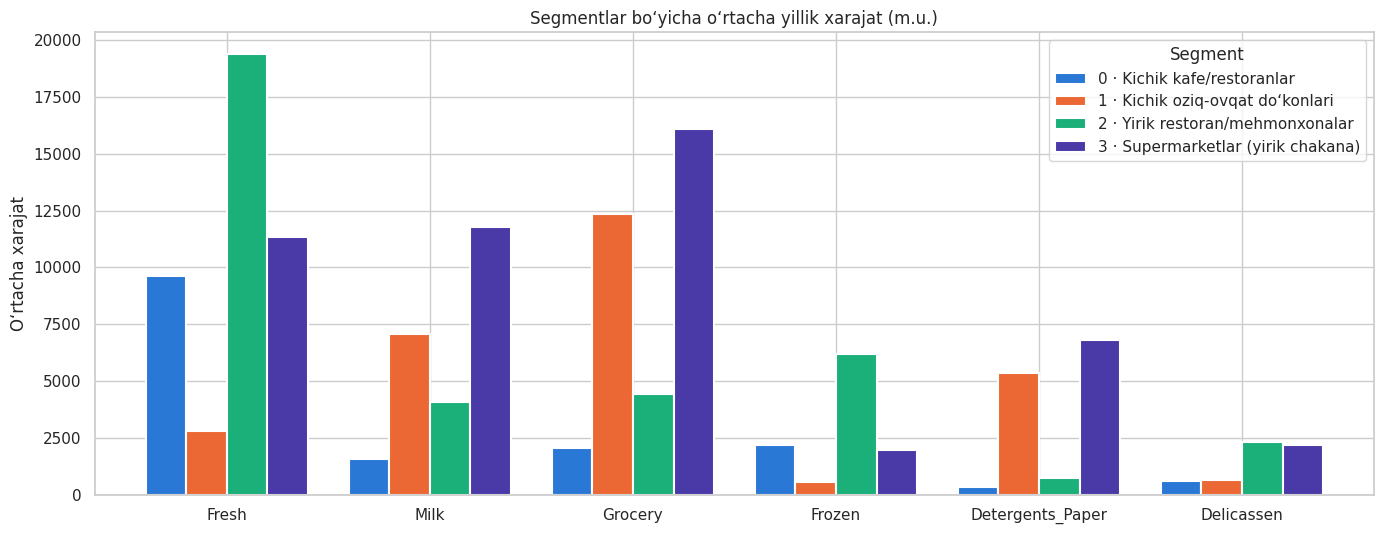

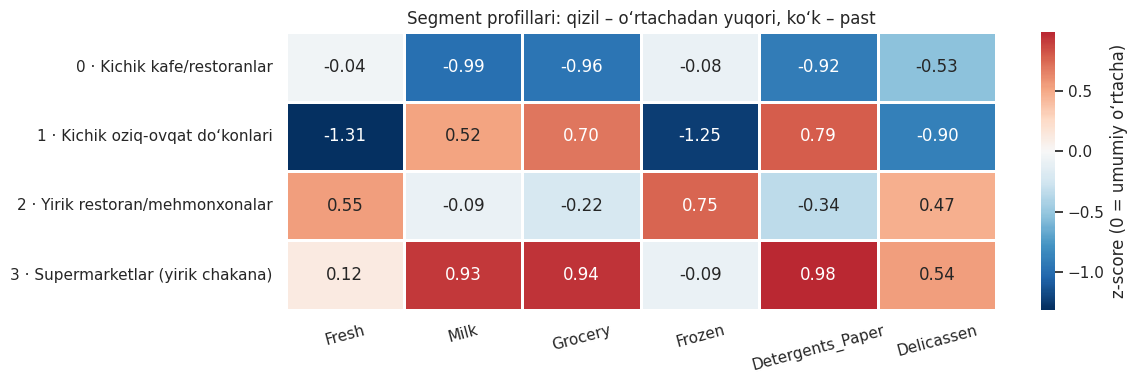

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Segment,,,,,,
0 · Kichik kafe/restoranlar,58.8,9.6,12.6,13.3,2.1,3.6
1 · Kichik oziq-ovqat doʻkonlari,9.8,24.6,42.9,2.0,18.6,2.2
2 · Yirik restoran/mehmonxonalar,52.2,11.0,12.0,16.7,1.9,6.3
3 · Supermarketlar (yirik chakana),22.6,23.5,32.1,3.9,13.6,4.3


In [14]:
# ===================== 6. SEGMENTLAR BOʻYICHA OʻRTACHA XARAJATLAR =====================
means = df.groupby("Segment")[spend_cols].mean().loc[seg_order]

# 6.1. Har bir segmentning har bir kategoriya boʻyicha oʻrtacha xarajati (asl summalarda)
ax = means.T.plot(kind="bar", figsize=(14, 5.5), width=0.8, edgecolor="white", linewidth=1.5,
                  color=[palette[s] for s in seg_order])
ax.set_title("Segmentlar boʻyicha oʻrtacha yillik xarajat (m.u.)")
ax.set_xlabel("")
ax.set_ylabel("Oʻrtacha xarajat")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Segment")
plt.tight_layout()
plt.show()

# 6.2. Nisbiy profil: har bir segment umumiy oʻrtachadan qancha farq qiladi (z-score, log-masshtab)
z = X_scaled_df.groupby(df["Segment"].values).mean().loc[seg_order]
plt.figure(figsize=(12, 4))
sns.heatmap(z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=1, linecolor="white",
            cbar_kws={"label": "z-score (0 = umumiy oʻrtacha)"})
plt.title("Segment profillari: qizil – oʻrtachadan yuqori, koʻk – past")
plt.ylabel("")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# 6.3. Har bir segment xarajatining kategoriyalar boʻyicha taqsimoti (%)
share = (means.div(means.sum(axis=1), axis=0) * 100).round(1)
share

## Xulosa va marketologlarga tavsiyalar

### 0 · Kichik kafe/restoranlar — 132 mijoz (30%)
- **Kimlar:** deyarli faqat HoReCa (131 ta).
- **Xarajat:** barcha kategoriyalarda eng past (oʻrtacha ≈16 ming); byudjetning ≈59% i yangi mahsulotlarga (Fresh).
- **Tavsiyalar:** kichik hajmli, tez-tez yetkazib berish; "kafe uchun starter-paket" (yangi + muzlatilgan + sut); minimal buyurtma chegarasini pasaytirish; sodiqlik dasturi orqali buyurtma hajmini oshirish.

### 1 · Kichik oziq-ovqat doʻkonlari — 61 mijoz (14%)
- **Kimlar:** asosan chakana savdo (40 ta).
- **Xarajat:** Grocery (≈43%), Milk (≈25%) va Detergents_Paper (≈19%) ustun; Fresh va Frozen juda past.
- **Tavsiyalar:** qadoqlangan oziq-ovqat va maishiy kimyo boʻyicha hajmli chegirmalar; yangi va muzlatilgan mahsulotlarni cross-sell qilish (sinov partiyalari, muzlatkich jihozi bilan aksiya).

### 2 · Yirik restoran/mehmonxonalar — 129 mijoz (29%)
- **Kimlar:** asosan HoReCa (122 ta).
- **Xarajat:** Fresh (≈19 ming), Frozen (≈6 ming) va Delicassen boʻyicha eng yuqori xarajat.
- **Tavsiyalar:** yangi va muzlatilgan mahsulotlar uchun uzoq muddatli shartnomalar va kafolatlangan kunlik yetkazib berish; premium delikates liniyasi; shaxsiy menejer (key account).

### 3 · Supermarketlar (yirik chakana) — 118 mijoz (27%)
- **Kimlar:** asosan chakana savdo (94 ta).
- **Xarajat:** eng yuqori umumiy xarajat (≈50 ming); Grocery, Milk va Detergents_Paper boʻyicha yetakchi.
- **Tavsiyalar:** eng qimmatli segment – ulgurji narx shkalasi va bonuslar; hamkorlikdagi aksiyalar (promo, javon joylashuvi); avtomatik qayta buyurtma tizimi; sut va kimyo mahsulotlarining yangi brendlarini birinchi boʻlib taklif qilish.

### Umumiy xulosalar
- Asosiy farq mahsulot turida: HoReCa mijozlari **yangi/muzlatilgan** mahsulotlarga, chakana savdo esa **oziq-ovqat, sut va kimyo/qogʻoz** mahsulotlariga pul sarflaydi. Shuning uchun marketing kampaniyalarini kanal boʻyicha alohida qurish kerak.
- Har bir kanal ichida *kichik* va *yirik* mijozlar bor: yiriklarni ushlab qolish (retention, shaxsiy xizmat), kichiklarni esa oʻstirish (upsell, cross-sell) strategiyasi samarali.
- `Region` boʻyicha taqsimot barcha segmentlarda deyarli bir xil (≈70% "Boshqa" hudud) – hududga emas, mijoz turi va xarajat odatiga qarab yondashish maqsadga muvofiq.